[**DISCLAIMER**]
The dataset used is downloaded from https://www.kaggle.com/datasets/janiobachmann/bank-marketing-dataset/data which in turn has given credit to [Moro et al., 2014] S. Moro, P. Cortez and P. Rita. A Data-Driven Approach to Predict the Success of Bank Telemarketing. Decision Support Systems, Elsevier, 62:22-31, June 2014

In [ ]:
#import file bank.csv into pandas df

import pandas as pd

df = pd.read_csv('bank.csv')
df
    

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11157,33,blue-collar,single,primary,no,1,yes,no,cellular,20,apr,257,1,-1,0,unknown,no
11158,39,services,married,secondary,no,733,no,no,unknown,16,jun,83,4,-1,0,unknown,no
11159,32,technician,single,secondary,no,29,no,no,cellular,19,aug,156,2,-1,0,unknown,no
11160,43,technician,married,secondary,no,0,no,yes,cellular,8,may,9,2,172,5,failure,no


In [4]:
# Check the target class distribution (deposit subscription).
target = df['deposit']
class_counts = target.value_counts().rename_axis('deposit')
class_distribution = class_counts.to_frame(name='count')
class_distribution['percentage'] = (class_counts / class_counts.sum() * 100).round(2)

print(f"Missing target values: {target.isna().sum():,}")
class_distribution

Missing target values: 0


,count,percentage
deposit,,
no,5873,52.62
yes,5289,47.38


In [5]:
# Quantify imbalance among the observed, non-missing classes.
majority_class = class_counts.idxmax()
majority_baseline = class_counts.max() / class_counts.sum()

if len(class_counts) > 1:
    imbalance_ratio = class_counts.max() / class_counts.min()
    print(f"Majority-to-minority class ratio: {imbalance_ratio:.2f}:1 (1:1 is balanced)")
else:
    print("Only one observed class; a class imbalance ratio is not defined.")

print(f"Majority-class accuracy baseline (always predict '{majority_class}'): {majority_baseline:.2%}")

Majority-to-minority class ratio: 1.11:1 (1:1 is balanced)
Majority-class accuracy baseline (always predict 'no'): 52.62%


### Feature distributions

Inspect numeric histograms over the full observed range and categorical count plots. The target `deposit` is excluded.

In [6]:
import matplotlib.pyplot as plt

features = df.drop(columns='deposit')
numeric_features = features.select_dtypes(include='number')

numeric_summary = numeric_features.describe().T[['min', '25%', '50%', '75%', 'max']]
numeric_summary = numeric_summary.rename(columns={'50%': 'median'})
numeric_summary['skewness'] = numeric_features.skew()
numeric_summary['missing'] = numeric_features.isna().sum()
numeric_summary.round(2)

,min,25%,median,75%,max,skewness,missing
age,18.0,32.0,39.0,49.00,95.0,0.86,0
balance,-6847.0,122.0,550.0,1708.00,81204.0,8.22,0
day,1.0,8.0,15.0,22.00,31.0,0.11,0
duration,2.0,138.0,255.0,496.00,3881.0,2.14,0
campaign,1.0,1.0,2.0,3.00,63.0,5.55,0
pdays,-1.0,-1.0,-1.0,20.75,854.0,2.45,0
previous,0.0,0.0,0.0,1.00,58.0,7.34,0


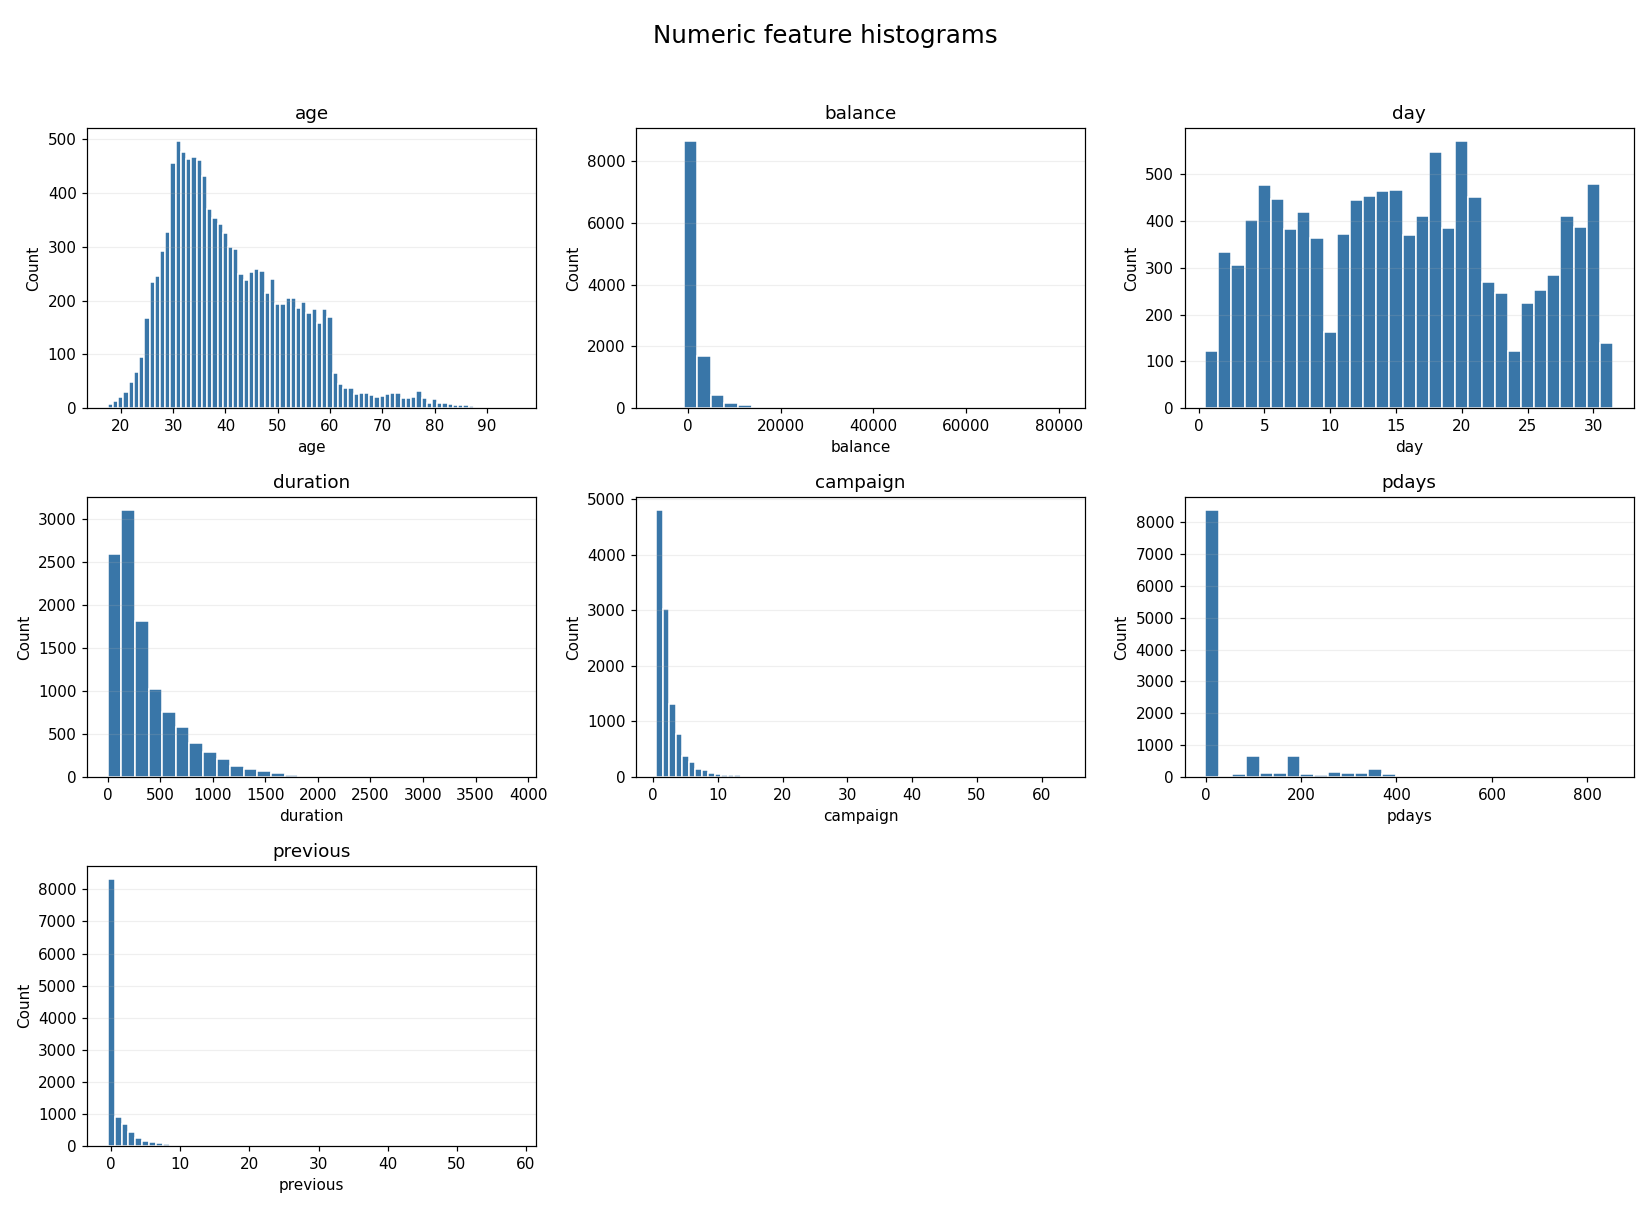

In [7]:
# Keep the full range so long tails and unusual values remain visible.
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, column in zip(axes.flat, numeric_features.columns):
    values = numeric_features[column].dropna()
    # Center bins on integers for age, day, and contact counts.
    bins = ([value - 0.5 for value in range(int(values.min()), int(values.max()) + 2)]
            if column in ['age', 'day', 'campaign', 'previous'] else 30)
    ax.hist(values, bins=bins, color='#3976a8', edgecolor='white')
    ax.set_title(column)
    ax.set_xlabel(column)
    ax.set_ylabel('Count')
    ax.grid(axis='y', alpha=0.2)

for ax in axes.flat[len(numeric_features.columns):]:
    ax.set_visible(False)

fig.suptitle('Numeric feature histograms', fontsize=16)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

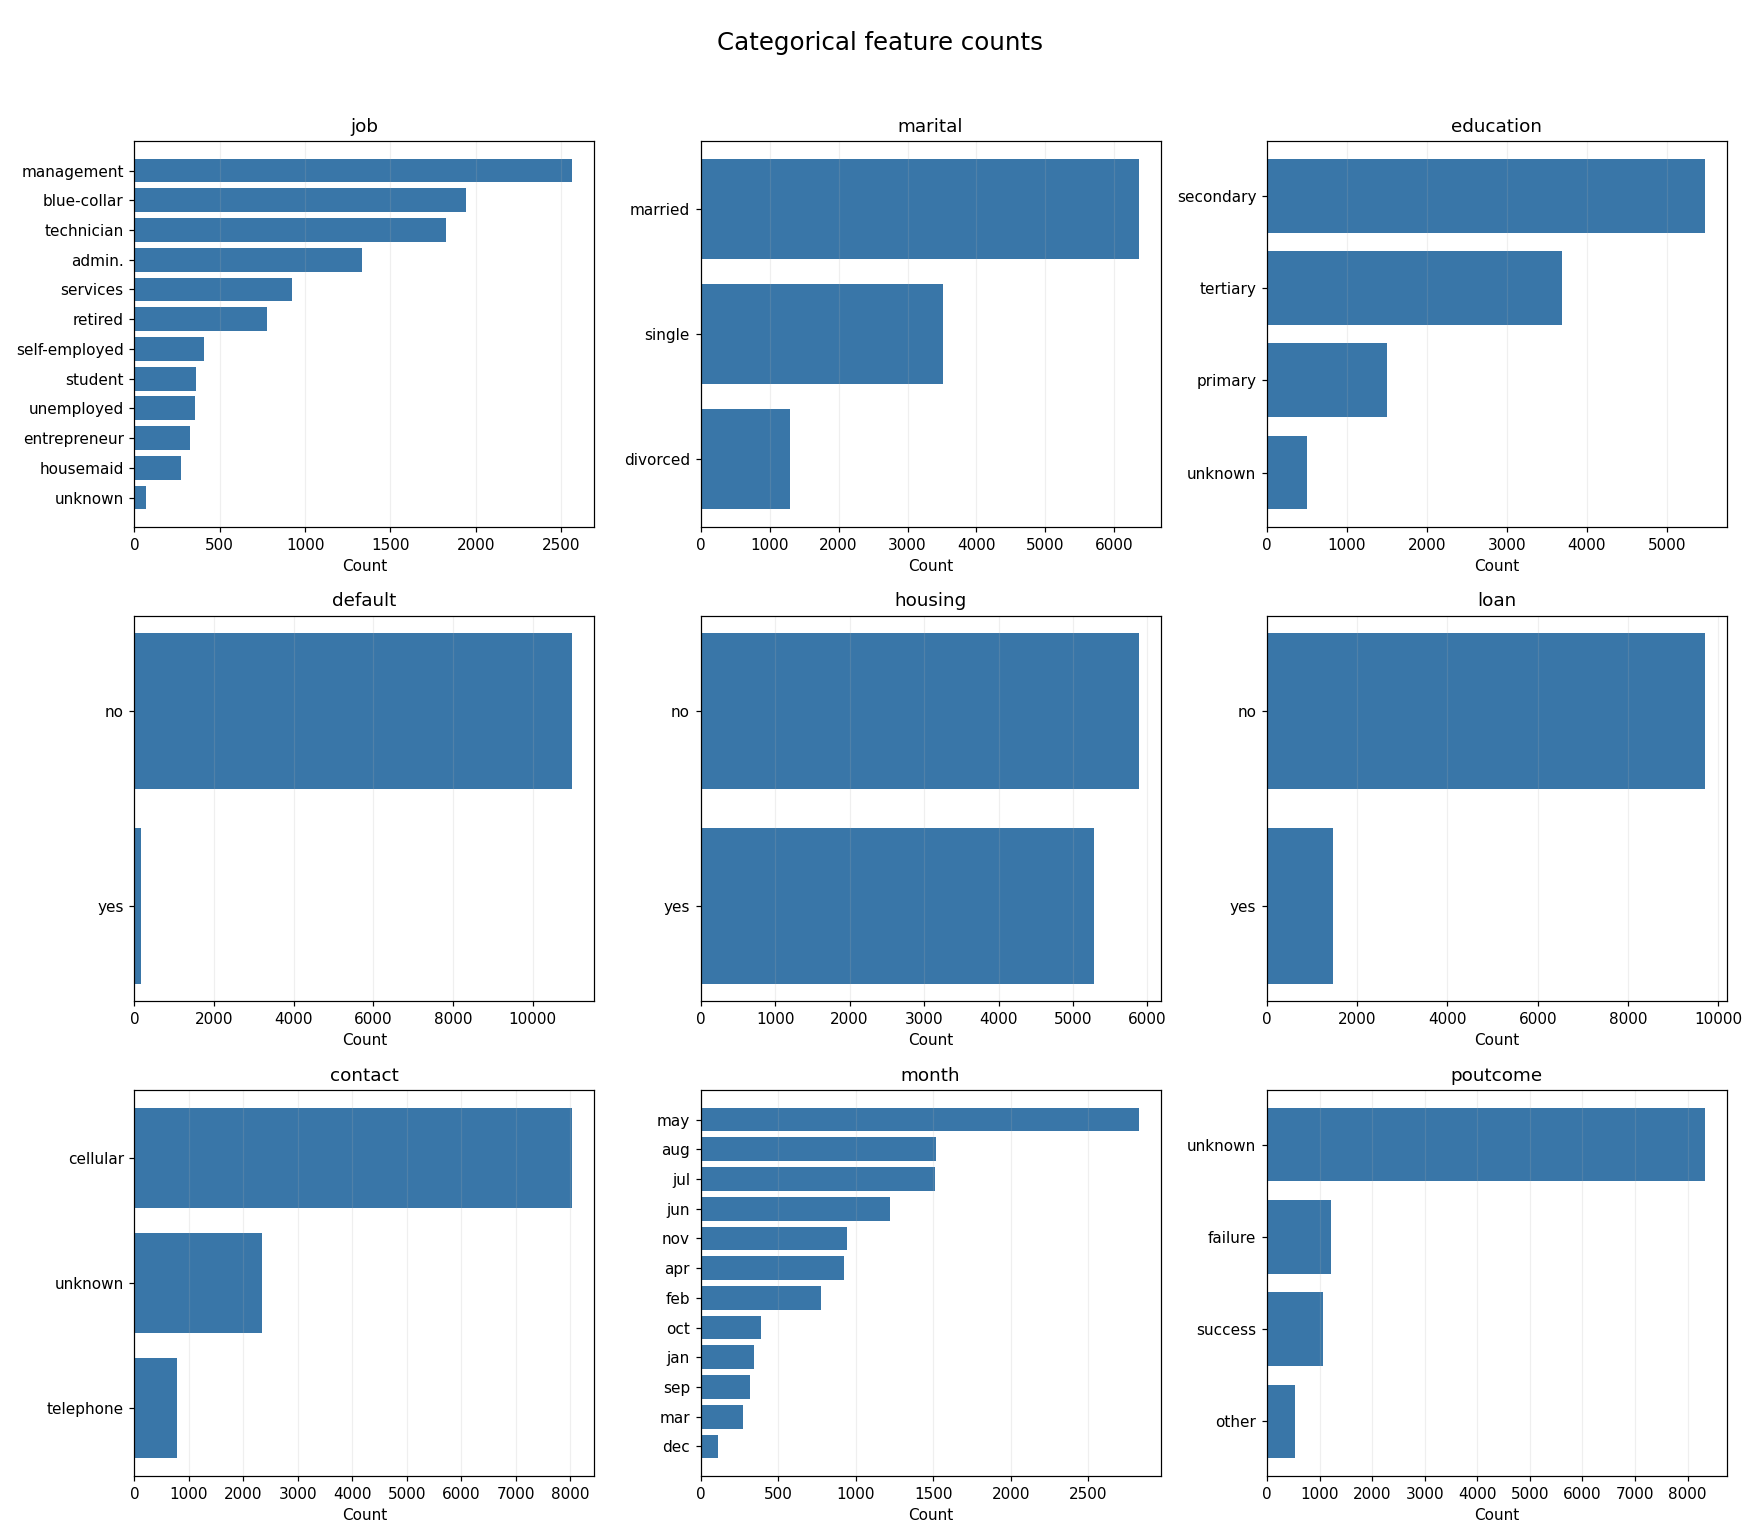

In [8]:
# Use category counts for nonnumeric features, including "unknown" values.
categorical_features = features.select_dtypes(exclude='number')
fig, axes = plt.subplots(3, 3, figsize=(16, 14))
for ax, column in zip(axes.flat, categorical_features.columns):
    counts = categorical_features[column].value_counts(dropna=False).sort_values()
    ax.barh(counts.index.astype(str), counts.values, color='#3976a8')
    ax.set_title(column)
    ax.set_xlabel('Count')
    ax.grid(axis='x', alpha=0.2)

for ax in axes.flat[len(categorical_features.columns):]:
    ax.set_visible(False)

fig.suptitle('Categorical feature counts', fontsize=16)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

**Observations from this dataset**

- `balance`, `duration`, `campaign`, `pdays`, and `previous` have long right tails. `balance` ranges from -6,847 to 81,204, with a median of 550; investigate extremes before deciding on transformations.
- `pdays` is -1 for 8,324 rows (74.57%), and `previous` is zero for the same rows. Treat the -1 spike separately when interpreting the `pdays` distribution.
- `age` has a moderate right tail; `day` has relatively little skew.
- Categorical features can be concentrated even with a balanced target: `default` is overwhelmingly "no", and `poutcome` is mostly "unknown". There are no missing numeric values.

These plots preserve the original data; no rows are removed or values transformed.